Constanza Pontillo 21.981.293-0

In [1]:
#importamos las librerias que usaremos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Parte I

In [2]:
rng = np.random.default_rng(seed = 6)#elegimos una semilla

In [3]:
radio_estelar = rng.uniform(0.5, 5, 100)#usamos nuestra semilla para que nos den nuestros datos conforme ella
distancia = rng.uniform(50, 500, 100)
temp_efectiva = rng.uniform(3000, 10000, 100)
#usamos rng.uniform de modo que (inicio, final, cantidad de datos)

In [4]:
numero_estrella = np.linspace(1,100,100)#creamos una variable que nos de numeros del 1 al 0 para identificar cada estrella

In [5]:
dict = {"Radio Estelar" : radio_estelar,
       "Distancia" : distancia,
       "Temperatura efectiva" : temp_efectiva}
#creamos un diccionario donde usaremos de key lo que deseamos que seran los nombres de la filas y los valores seran los datos que definimos anteriormente

In [6]:
df = pd.DataFrame(dict, index=numero_estrella)#usamos las funciones de pandas para crear un DataFrame(tabla bidimensional) y le damos que sus indices seran el numero de estrella para saber de que estrella es cada dato

In [7]:
df[["Radio Estelar", "Distancia", "Temperatura efectiva"]].describe()#la funcion describe nos ahorra un monton de tiempo para sacar informacion de nuestra tabala como el promedio, desviacion, minimo, maximo, cuartiles, es mucho mas rapido uqe ir buscando uno por uno

,Radio Estelar,Distancia,Temperatura efectiva
count,100.000000,100.000000,100.000000
mean,2.921506,278.533955,6445.599066
std,1.343874,133.042189,2023.620514
min,0.523909,55.387330,3065.823774
25%,1.739997,159.759827,4612.920825
50%,2.924176,286.078109,6353.088241
75%,4.222096,398.846589,8175.479166
max,4.972083,498.187472,9902.183715


In [8]:
display(df.head(10))#funcion .head(10) nos da los primeros 10 valores

,Radio Estelar,Distancia,Temperatura efectiva
1.0,2.921740,479.190807,9668.391101
2.0,2.044719,229.879702,8156.022600
3.0,2.160803,133.640644,5857.183573
4.0,2.185235,185.258510,4041.853846
5.0,4.943502,100.764997,7781.833064
6.0,3.347403,397.319412,7011.711081
7.0,3.534458,178.390775,9028.213838
8.0,1.984836,361.983242,4792.891850
9.0,3.559629,257.406841,7598.279279
10.0,1.053376,106.237865,3654.414830


Parte II

In [9]:
sigma = 5.67e-8 #constante de Stefan-Boltzmann
radio_metros = radio_estelar * 6.957e8 #cambiamos de sistema de unidades
mts = distancia * 3.086 * 10**16 #cambiamos de sistema de unidades

luminosidad = 4 * np.pi * (radio_metros)**2 * sigma * (temp_efectiva**4) #formula de la luminosidad

flujo = luminosidad / (4 * np.pi * (mts**2)) #obtenemos el flujo

In [10]:
#agregamos las filas nuevas ["nombre"] = de donde sacara los datos
df["Luminosidad"] = luminosidad
df["Flujo observado"] = flujo

In [11]:
df.sort_values("Luminosidad", ascending=False)#ordenamos la parte de luminosidad

,Radio Estelar,Distancia,Temperatura efectiva,Luminosidad,Flujo observado
54.0,4.881312,68.189461,9441.434111,6.529230e+28,1.173345e-09
46.0,4.526217,393.856861,9622.933343,6.058115e+28,3.263315e-11
16.0,4.033449,309.392394,9902.183715,5.394039e+28,4.708614e-11
70.0,4.591537,329.257144,9126.540024,5.044031e+28,3.887815e-11
34.0,4.491340,209.206406,8966.529183,4.496621e+28,8.584888e-11
...,...,...,...,...,...
100.0,1.398778,443.883520,3760.649890,1.349542e+26,5.723302e-14
11.0,0.732782,314.260452,5166.845704,1.319739e+26,1.116624e-13
77.0,1.393626,389.207892,3304.898617,7.990278e+25,4.407546e-14
10.0,1.053376,106.237865,3654.414830,6.824564e+25,5.052595e-13


In [12]:
df.sort_values("Flujo observado", ascending=False)#ordenamos la parte de flujo 

,Radio Estelar,Distancia,Temperatura efectiva,Luminosidad,Flujo observado
54.0,4.881312,68.189461,9441.434111,6.529230e+28,1.173345e-09
31.0,3.140823,85.352833,9671.986625,2.977053e+28,3.414671e-10
5.0,4.943502,100.764997,7781.833064,3.090538e+28,2.543390e-10
28.0,4.397837,68.781669,6223.432808,1.000542e+28,1.767210e-10
15.0,4.221514,103.131680,7332.228688,1.776304e+28,1.395505e-10
...,...,...,...,...,...
59.0,1.734218,350.062264,3517.731459,1.588162e+26,1.082935e-13
38.0,1.741924,453.398898,3612.978570,1.783023e+26,7.247602e-14
100.0,1.398778,443.883520,3760.649890,1.349542e+26,5.723302e-14
77.0,1.393626,389.207892,3304.898617,7.990278e+25,4.407546e-14


Parte III

In [13]:
flujo_lim = 2 * (10**-10)#definimos el flujo limite (condicion)

In [14]:
df["Clasificacion"] = df["Flujo observado"].apply(lambda x: "detectada" if x >= flujo_lim else "no detectada")
#agregamos una nueva columna y ademas filtramos que va tener cada columna si esta detectada o no dependiendo si cumple la condicion del flujo limite

In [15]:
print(df)

       Radio Estelar   Distancia  Temperatura efectiva   Luminosidad  \
1.0         2.921740  479.190807           9668.391101  2.572390e+28   
2.0         2.044719  229.879702           8156.022600  6.379958e+27   
3.0         2.160803  133.640644           5857.183573  1.895058e+27   
4.0         2.185235  185.258510           4041.853846  4.394969e+26   
5.0         4.943502  100.764997           7781.833064  3.090538e+28   
...              ...         ...                   ...           ...   
96.0        1.436981  218.649060           6268.771853  1.099687e+27   
97.0        0.881347   80.358010           5718.635432  2.864839e+26   
98.0        3.795034  196.645792           7759.681273  1.800710e+28   
99.0        4.173828  339.213721           3065.823774  5.307557e+26   
100.0       1.398778  443.883520           3760.649890  1.349542e+26   

       Flujo observado Clasificacion  
1.0       9.360911e-12  no detectada  
2.0       1.008823e-11  no detectada  
3.0       8.866325

In [16]:
cant_detectadas = (df["Clasificacion"]=="detectada").sum()#obtenemos la cantidad de detectadas
total = len(df) #total de datos dados, podriamos poner dictamente 100, pero para generalizar mas el ejercicio 
porcentaje = (cant_detectadas/total) * 100 # obtebermos el porcentaje
print(porcentaje)

3.0


In [17]:
#guardamos en variables las dectadas y las no detectadas
df_detectadas = df[df["Clasificacion"] == "detectada"]
df_nodetectadas = df[df["Clasificacion"] == "no detectada"]

In [18]:
#grupo detectadas
dectectadas_flujo = df_detectadas["Flujo observado"].mean()#sacamos el promedio del flujo 
dectectadas_dist = df_detectadas["Distancia"].mean()#sacamos el promedio de la distancia
dectectadas_temp = df_detectadas["Temperatura efectiva"].mean()#sacamos el promedio de la temperatura efectiva

print(dectectadas_flujo, dectectadas_dist, dectectadas_temp)

5.897170739191611e-10 84.76909672138277 8965.0845998185


In [19]:
#grupo no detectadas
nodectectadas_flujo = df_nodetectadas["Flujo observado"].mean()#sacamos el promedio del flujo 
nodectectadas_dist = df_nodetectadas["Distancia"].mean()#sacamos el promedio de la distancia
nodectectadas_temp = df_nodetectadas["Temperatura efectiva"].mean()#sacamos el promedio de la temperatura efectiva

print(nodectectadas_flujo, nodectectadas_dist, nodectectadas_temp)

1.6958343061046012e-11 284.5266830483031 6367.6768333119135


Text(0, 0.5, 'Frecuencia')

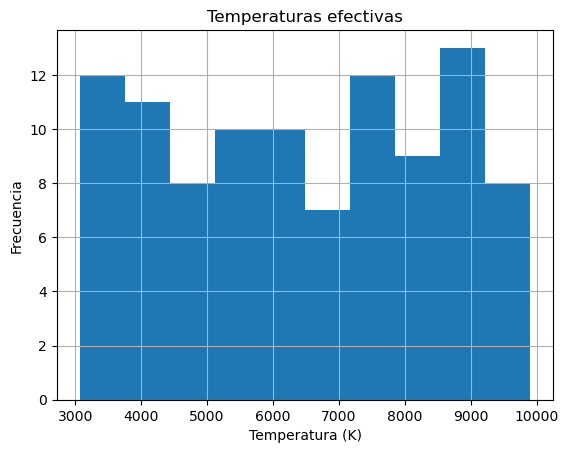

In [20]:
df["Temperatura efectiva"].hist()#hacemos un histograma
plt.title("Temperaturas efectivas")#ponemos titulo 
plt.xlabel("Temperatura (K)")#ponemos titulo a los ejes
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

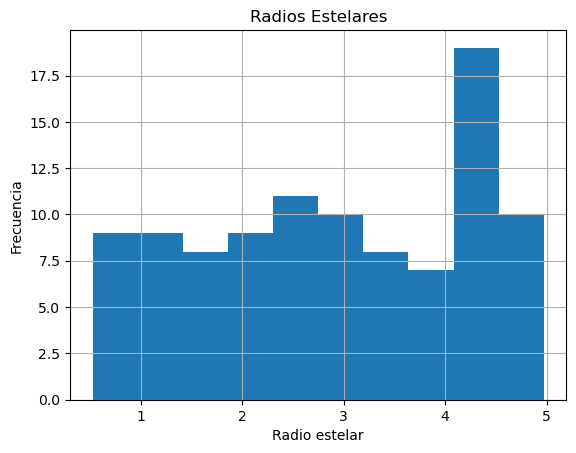

In [21]:
df["Radio Estelar"].hist()#hacemos un histograma
plt.title("Radios Estelares")#ponemos titulo 
plt.xlabel("Radio estelar")#ponemos titulo a los ejes
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

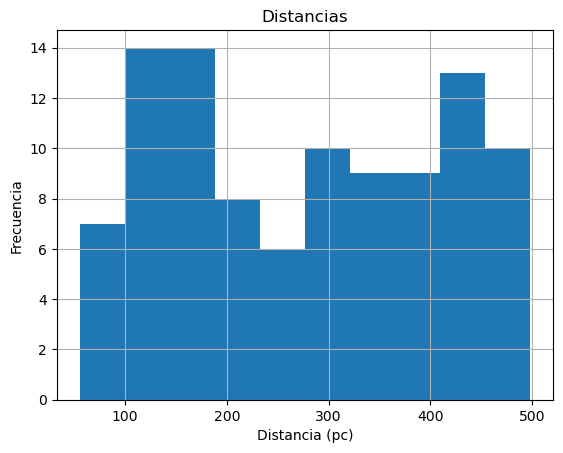

In [22]:
df["Distancia"].hist()#hacemos un histograma
plt.title("Distancias")#ponemos titulo 
plt.xlabel("Distancia (pc)")#ponemos titulo a los ejes
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

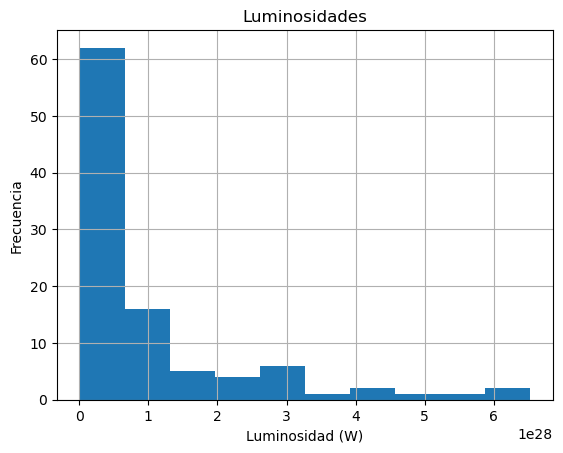

In [23]:
df["Luminosidad"].hist()#hacemos un histograma
plt.title("Luminosidades")#ponemos titulo 
plt.xlabel("Luminosidad (W)")#ponemos titulo a los ejes
plt.ylabel("Frecuencia")

Text(0, 0.5, 'Frecuencia')

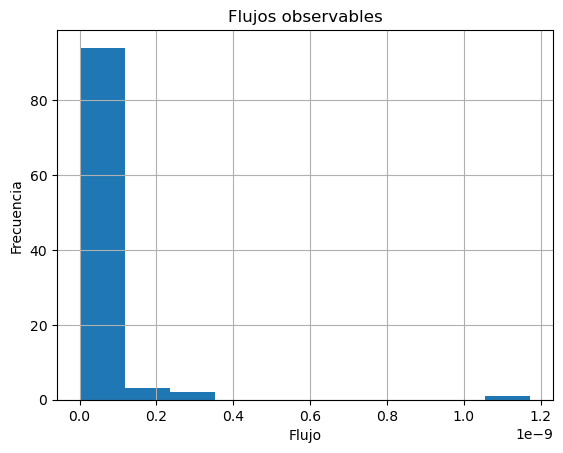

In [24]:
df["Flujo observado"].hist()#hacemos un histograma
plt.title("Flujos observables")#ponemos titulo 
plt.xlabel("Flujo")#ponemos titulo a los ejes
plt.ylabel("Frecuencia")

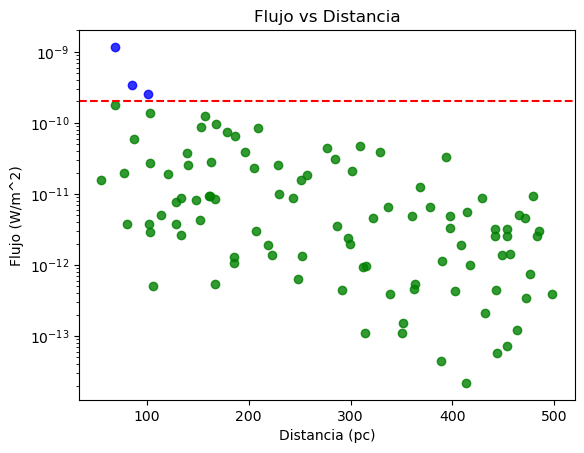

In [25]:
#definimos las detectadas y las no detectadas
detectadas = df[df["Clasificacion"] == "detectada"]
no_detectadas = df[df["Clasificacion"] == "no detectada"]

plt.scatter(detectadas["Distancia"], detectadas["Flujo observado"], color="blue", alpha=0.8)#creamos un grafico y ponemos los datos de forma que: dato que bucamos["que necesitamos de este dato"], y agregamos color
plt.scatter(no_detectadas["Distancia"], no_detectadas["Flujo observado"], color="green", alpha=0.8)

plt.axhline(y=flujo_lim, color="red", linestyle="--")#agregamos linea que marca el limite de detecccion

plt.yscale("log")#escala logaritmica
plt.title("Flujo vs Distancia")#agregamos titulos 
plt.xlabel("Distancia (pc)")
plt.ylabel("Flujo (W/m^2)")

plt.show()

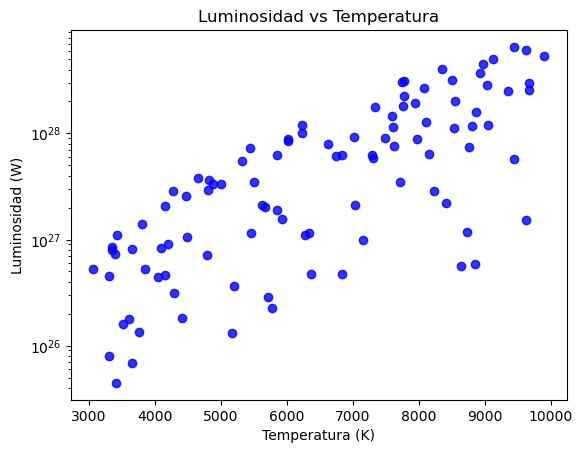

In [26]:
plt.scatter(df["Temperatura efectiva"], df["Luminosidad"], color="blue", alpha=0.8)#creamos el grafico y le damos sus variables en el orden de x , y

plt.yscale("log")#escala logaritmica
plt.title("Luminosidad vs Temperatura")#agregamos titulos
plt.xlabel("Temperatura (K)")
plt.ylabel("Luminosidad (W)")

plt.show()